# About the Dataset: IoT-23 - Labeled Dataset of IoT Network Traffic

🔗 [Dataset Link] (https://www.kaggle.com/datasets/agungpambudi/network-malware-detection-connection-analysis/data?select=CTU-IoT-Malware-Capture-1-1conn.log.labeled.csv)

To cite this dataset, please use the following reference:

> **Stratosphere Laboratory.**  
> *A labeled dataset with malicious and benign IoT network traffic.*  
> **January 22th**  
> **Authors:** Agustin Parmisano, Sebastian Garcia, Maria Jose Erquiaga  
> 🔗 [https://www.stratosphereips.org/datasets-iot23](https://www.stratosphereips.org/datasets-iot23)

---

## Dataset Description

This dataset includes **labels** that explain the linkages between flows connected with **malicious or potentially malicious activity**, created through **manual analysis** in the **Stratosphere Laboratory** using malware capture techniques.

The goal is to support **malware researchers and network analysts** in understanding attack patterns in IoT environments.

---

## Label Definitions

| Label                     | Description |
|---------------------------|-------------|
| **Attack**                | The infected device initiates an attack (e.g., brute-force login, command injection). |
| **Benign**                | No malicious or suspicious activity detected. |
| **C&C (Command & Control)** | Infected device connects to C2 server, often with periodic behavior or command exchange. |
| **DDoS**                  | Involvement in a Distributed Denial of Service attack. High flow volume to a single IP. |
| **FileDownload**          | File being downloaded to the device (large response bytes, suspicious IPs/ports). |
| **HeartBeat**             | Periodic small-byte connections used to track infected host by C2 server. |
| **Mirai**                 | Behavior matches the known pattern of the Mirai botnet. |
| **Okiru**                 | Similar to Mirai, but represents the Okiru botnet family. |
| **PartOfAHorizontalPortScan** | Part of a port scan targeting multiple IPs with similar port/byte patterns. |
| **Torii**                 | Matches behavior of the Torii botnet (less common than Mirai). |

---

## Dataset Fields

| Field Name         | Description                                                                 | Type       |
|--------------------|-----------------------------------------------------------------------------|------------|
| **ts**             | Timestamp of the connection event.                                          | time       |
| **uid**            | Unique identifier for the connection.                                       | string     |
| **id.orig_h**      | Source IP address.                                                          | addr       |
| **id.orig_p**      | Source port.                                                                | port       |
| **id.resp_h**      | Destination IP address.                                                     | addr       |
| **id.resp_p**      | Destination port.                                                           | port       |
| **proto**          | Network protocol used (e.g., TCP, UDP).                                     | enum       |
| **service**        | Application/service protocol.                                               | string     |
| **duration**       | Duration of the connection.                                                 | interval   |
| **orig_bytes**     | Bytes sent from source to destination.                                      | count      |
| **resp_bytes**     | Bytes sent from destination to source.                                      | count      |
| **conn_state**     | State of the connection (e.g., established, failed, etc.).                  | string     |
| **local_orig**     | Whether the connection originated locally.                                  | bool       |
| **local_resp**     | Whether the connection response was local.                                  | bool       |
| **missed_bytes**   | Number of bytes missed in the connection.                                   | count      |
| **history**        | History of connection states.                                               | string     |
| **orig_pkts**      | Packets sent from source to destination.                                    | count      |
| **orig_ip_bytes**  | IP bytes sent from source to destination.                                   | count      |
| **resp_pkts**      | Packets sent from destination to source.                                    | count      |
| **resp_ip_bytes**  | IP bytes sent from destination to source.                                   | count      |
| **tunnel_parents** | Indicates whether the connection is part of a tunnel.                       | set[string]|
| **label**          | General label (e.g., *Malicious*, *Benign*).                                | string     |
| **detailed-label** | Specific description of the connection (e.g., *Mirai*, *Torii*, etc.).      | string     |

---

## Use Cases

This dataset is ideal for:

- Intrusion Detection Systems (IDS)
- Network Forensics
- Botnet Detection
- Supervised Machine Learning classification of malicious traffic

---

**Source:** [Stratosphere IPS - IoT23 Dataset](https://www.stratosphereips.org/datasets-iot23)


In [60]:
import pandas as pd
import numpy as np

In [61]:
file_path = 'data/CTU-IoT-Malware-Capture-1-1conn.log.labeled.csv'

In [62]:
original_df = pd.read_csv(file_path, delimiter='|')

In [63]:
original_df.head()

,ts,uid,id.orig_h,id.orig_p,id.resp_h,id.resp_p,proto,service,duration,orig_bytes,...,local_resp,missed_bytes,history,orig_pkts,orig_ip_bytes,resp_pkts,resp_ip_bytes,tunnel_parents,label,detailed-label
0,1.525880e+09,CUmrqr4svHuSXJy5z7,192.168.100.103,51524.0,65.127.233.163,23.0,tcp,-,2.999051,0,...,-,0.0,S,3.0,180.0,0.0,0.0,-,Malicious,PartOfAHorizontalPortScan
1,1.525880e+09,CH98aB3s1kJeq6SFOc,192.168.100.103,56305.0,63.150.16.171,23.0,tcp,-,-,-,...,-,0.0,S,1.0,60.0,0.0,0.0,-,Malicious,PartOfAHorizontalPortScan
2,1.525880e+09,C3GBTkINvXNjVGtN5,192.168.100.103,41101.0,111.40.23.49,23.0,tcp,-,-,-,...,-,0.0,S,1.0,60.0,0.0,0.0,-,Malicious,PartOfAHorizontalPortScan
3,1.525880e+09,CDe43c1PtgynajGI6,192.168.100.103,60905.0,131.174.215.147,23.0,tcp,-,2.998796,0,...,-,0.0,S,3.0,180.0,0.0,0.0,-,Malicious,PartOfAHorizontalPortScan
4,1.525880e+09,CJaDcG3MZzvf1YVYI4,192.168.100.103,44301.0,91.42.47.63,23.0,tcp,-,-,-,...,-,0.0,S,1.0,60.0,0.0,0.0,-,Malicious,PartOfAHorizontalPortScan


In [64]:
original_df.shape

(1008748, 23)

###  Generating a random sample of 200000 data

In [65]:
random_sample_df = original_df.sample(n=200000, random_state=42)

# Create a copy of the randomly sampled DataFrame to avoid modifying the original data.
df = random_sample_df.copy()

### Data Preprocessing

In [66]:
df.head()

,ts,uid,id.orig_h,id.orig_p,id.resp_h,id.resp_p,proto,service,duration,orig_bytes,...,local_resp,missed_bytes,history,orig_pkts,orig_ip_bytes,resp_pkts,resp_ip_bytes,tunnel_parents,label,detailed-label
344375,1.526010e+09,Cq6FWN3Ywzs95oALG2,192.168.100.103,53854.0,120.10.164.48,23.0,tcp,-,-,-,...,-,0.0,S,1.0,60.0,0.0,0.0,-,Malicious,PartOfAHorizontalPortScan
883270,1.526229e+09,Co0sIV2OSOJECc0jE3,192.168.100.103,36495.0,61.182.158.196,9527.0,tcp,-,-,-,...,-,0.0,S,1.0,60.0,0.0,0.0,-,Malicious,PartOfAHorizontalPortScan
94977,1.525915e+09,C4rbZX3Ybr3osgdch6,192.168.100.103,56144.0,107.159.11.133,9527.0,tcp,-,0.998941,0,...,-,0.0,S,2.0,120.0,0.0,0.0,-,Malicious,PartOfAHorizontalPortScan
552763,1.526090e+09,Cw5ilM1d22NAOq9zR1,192.168.100.103,43763.0,172.180.210.202,41534.0,udp,-,-,-,...,-,0.0,D,1.0,40.0,0.0,0.0,-,Benign,-
796999,1.526191e+09,CWBbvj2n84ONnUk1Pg,192.168.100.103,40038.0,134.153.182.254,2323.0,tcp,-,-,-,...,-,0.0,S,1.0,60.0,0.0,0.0,-,Malicious,PartOfAHorizontalPortScan


In [67]:
# Replace hyphens ('-') with pandas' NA values for better handling of missing or undefined data.
df.replace('-', pd.NA, inplace=True)

print(df.head())

                  ts                 uid        id.orig_h  id.orig_p  \
344375  1.526010e+09  Cq6FWN3Ywzs95oALG2  192.168.100.103    53854.0   
883270  1.526229e+09  Co0sIV2OSOJECc0jE3  192.168.100.103    36495.0   
94977   1.525915e+09  C4rbZX3Ybr3osgdch6  192.168.100.103    56144.0   
552763  1.526090e+09  Cw5ilM1d22NAOq9zR1  192.168.100.103    43763.0   
796999  1.526191e+09  CWBbvj2n84ONnUk1Pg  192.168.100.103    40038.0   

              id.resp_h  id.resp_p proto service  duration orig_bytes  ...  \
344375    120.10.164.48       23.0   tcp    <NA>      <NA>       <NA>  ...   
883270   61.182.158.196     9527.0   tcp    <NA>      <NA>       <NA>  ...   
94977    107.159.11.133     9527.0   tcp    <NA>  0.998941          0  ...   
552763  172.180.210.202    41534.0   udp    <NA>      <NA>       <NA>  ...   
796999  134.153.182.254     2323.0   tcp    <NA>      <NA>       <NA>  ...   

       local_resp missed_bytes history orig_pkts  orig_ip_bytes resp_pkts  \
344375       <NA>    

In [68]:
df.head()

,ts,uid,id.orig_h,id.orig_p,id.resp_h,id.resp_p,proto,service,duration,orig_bytes,...,local_resp,missed_bytes,history,orig_pkts,orig_ip_bytes,resp_pkts,resp_ip_bytes,tunnel_parents,label,detailed-label
344375,1.526010e+09,Cq6FWN3Ywzs95oALG2,192.168.100.103,53854.0,120.10.164.48,23.0,tcp,<NA>,<NA>,<NA>,...,<NA>,0.0,S,1.0,60.0,0.0,0.0,<NA>,Malicious,PartOfAHorizontalPortScan
883270,1.526229e+09,Co0sIV2OSOJECc0jE3,192.168.100.103,36495.0,61.182.158.196,9527.0,tcp,<NA>,<NA>,<NA>,...,<NA>,0.0,S,1.0,60.0,0.0,0.0,<NA>,Malicious,PartOfAHorizontalPortScan
94977,1.525915e+09,C4rbZX3Ybr3osgdch6,192.168.100.103,56144.0,107.159.11.133,9527.0,tcp,<NA>,0.998941,0,...,<NA>,0.0,S,2.0,120.0,0.0,0.0,<NA>,Malicious,PartOfAHorizontalPortScan
552763,1.526090e+09,Cw5ilM1d22NAOq9zR1,192.168.100.103,43763.0,172.180.210.202,41534.0,udp,<NA>,<NA>,<NA>,...,<NA>,0.0,D,1.0,40.0,0.0,0.0,<NA>,Benign,<NA>
796999,1.526191e+09,CWBbvj2n84ONnUk1Pg,192.168.100.103,40038.0,134.153.182.254,2323.0,tcp,<NA>,<NA>,<NA>,...,<NA>,0.0,S,1.0,60.0,0.0,0.0,<NA>,Malicious,PartOfAHorizontalPortScan


### Handling null values

In [69]:
df.isnull().sum()

ts                     0
uid                    0
id.orig_h              0
id.orig_p              0
id.resp_h              0
id.resp_p              0
proto                  0
service           199352
duration          157977
orig_bytes        157977
resp_bytes        157977
conn_state             0
local_orig        200000
local_resp        200000
missed_bytes           0
history             3434
orig_pkts              0
orig_ip_bytes          0
resp_pkts              0
resp_ip_bytes          0
tunnel_parents    200000
label                  0
detailed-label     93057
dtype: int64

In [70]:
null_values = df.isnull().sum()

In [71]:
import matplotlib.pyplot as plt
import seaborn as sns

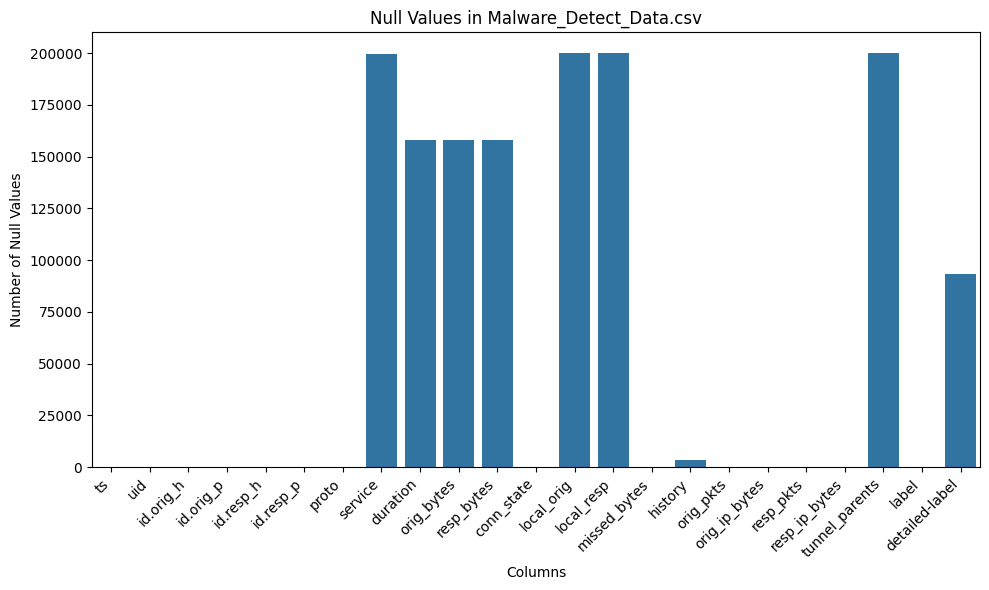

In [72]:
# Plotting null values using seaborn
plt.figure(figsize=(10, 6))
sns.barplot(x=null_values.index, y=null_values)
plt.xticks(rotation=45, ha='right')
plt.xlabel('Columns')
plt.ylabel('Number of Null Values')
plt.title('Null Values in Malware_Detect_Data.csv')
plt.tight_layout()
plt.show()

### Heat map

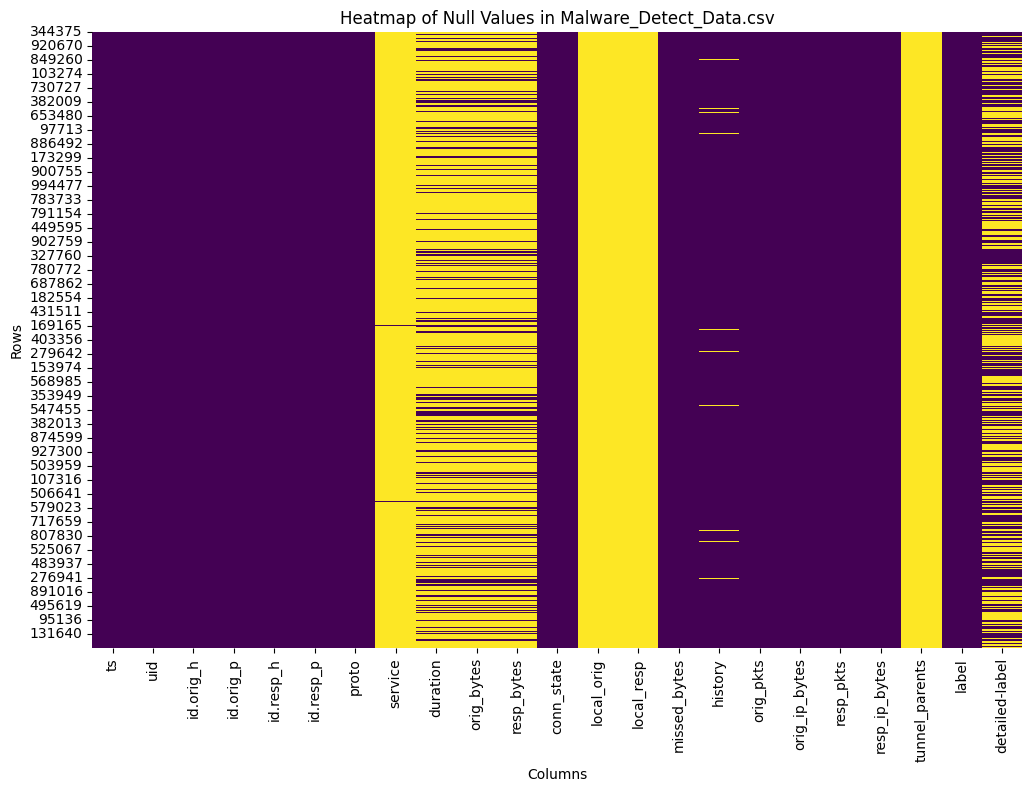

In [73]:
# Generate a heatmap of null values
plt.figure(figsize=(12, 8))
sns.heatmap(df.isnull(), cmap='viridis', cbar=False)
plt.xlabel('Columns')
plt.ylabel('Rows')
plt.title('Heatmap of Null Values in Malware_Detect_Data.csv')
plt.show()

### Calculating the null values as a percentage¶

In [74]:
null_values = df.isnull().sum()

null_percentage = (null_values / len(df)) * 100

columns_with_null = null_percentage[null_percentage > 0]

print("Columns with Null Values (Percentage):")
print(columns_with_null)

Columns with Null Values (Percentage):
service            99.6760
duration           78.9885
orig_bytes         78.9885
resp_bytes         78.9885
local_orig        100.0000
local_resp        100.0000
history             1.7170
tunnel_parents    100.0000
detailed-label     46.5285
dtype: float64


### Dropping column with null values that can not be replaced

In [75]:
# droping columns with null values
df.drop(['service','orig_bytes','resp_bytes','local_orig','local_resp','tunnel_parents'],axis=1,inplace=True)

### After dropiing the columns

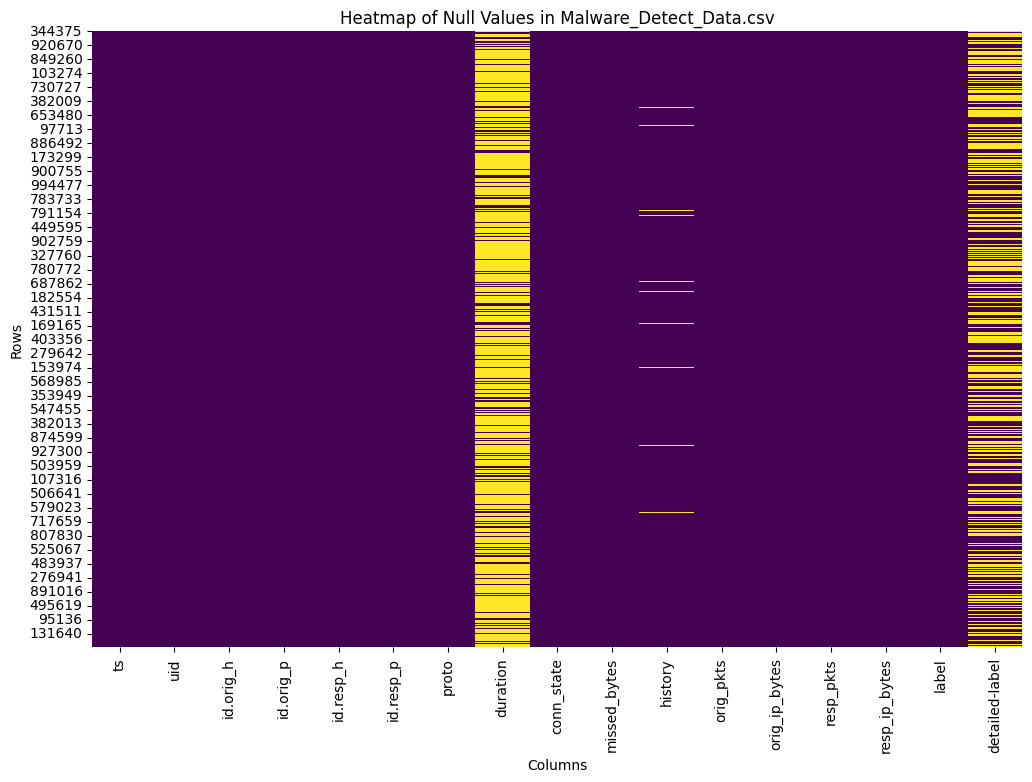

In [76]:
#Generate a heatmap of null values
plt.figure(figsize=(12, 8))
sns.heatmap(df.isnull(), cmap='viridis', cbar=False)
plt.xlabel('Columns')
plt.ylabel('Rows')
plt.title('Heatmap of Null Values in Malware_Detect_Data.csv')
plt.show()

### Handling null values in duration

In [77]:
df.head()

,ts,uid,id.orig_h,id.orig_p,id.resp_h,id.resp_p,proto,duration,conn_state,missed_bytes,history,orig_pkts,orig_ip_bytes,resp_pkts,resp_ip_bytes,label,detailed-label
344375,1.526010e+09,Cq6FWN3Ywzs95oALG2,192.168.100.103,53854.0,120.10.164.48,23.0,tcp,<NA>,S0,0.0,S,1.0,60.0,0.0,0.0,Malicious,PartOfAHorizontalPortScan
883270,1.526229e+09,Co0sIV2OSOJECc0jE3,192.168.100.103,36495.0,61.182.158.196,9527.0,tcp,<NA>,S0,0.0,S,1.0,60.0,0.0,0.0,Malicious,PartOfAHorizontalPortScan
94977,1.525915e+09,C4rbZX3Ybr3osgdch6,192.168.100.103,56144.0,107.159.11.133,9527.0,tcp,0.998941,S0,0.0,S,2.0,120.0,0.0,0.0,Malicious,PartOfAHorizontalPortScan
552763,1.526090e+09,Cw5ilM1d22NAOq9zR1,192.168.100.103,43763.0,172.180.210.202,41534.0,udp,<NA>,S0,0.0,D,1.0,40.0,0.0,0.0,Benign,<NA>
796999,1.526191e+09,CWBbvj2n84ONnUk1Pg,192.168.100.103,40038.0,134.153.182.254,2323.0,tcp,<NA>,S0,0.0,S,1.0,60.0,0.0,0.0,Malicious,PartOfAHorizontalPortScan


In [78]:
from sklearn import preprocessing

In [79]:
label_encoder = preprocessing.LabelEncoder()
#label encode label
df['label']= label_encoder.fit_transform(df['label'])
df.head()
df['duration'] = pd.to_numeric(df['duration'])

###  Checking for the correlation

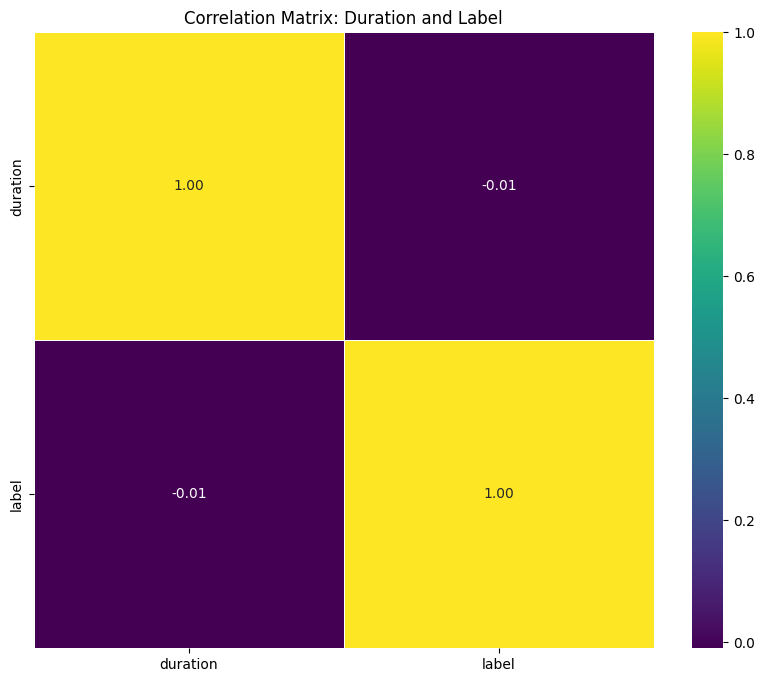

In [80]:
selected_columns = ['duration', 'label']

# Create a DataFrame with only the selected columns
selected_df = df[selected_columns]

# Calculate the correlation matrix
correlation_matrix = selected_df.corr()

plt.figure(figsize=(10, 8))

# Plot a heatmap of the correlation matrix
sns.heatmap(correlation_matrix, annot=True, cmap='viridis', fmt=".2f", linewidths=0.5)

plt.title('Correlation Matrix: Duration and Label')

plt.show()

### Drop the duration column also

In [81]:
df['duration'].value_counts()

duration
2.998791    853
2.998790    846
2.998792    809
2.998793    743
2.998789    683
           ... 
0.842996      1
2.999417      1
0.754569      1
2.787161      1
0.886021      1
Name: count, Length: 4597, dtype: int64

In [82]:
df['duration'].nunique()

4597

In [83]:
df.drop(['duration'],axis=1,inplace=True)

In [84]:
df.head()

,ts,uid,id.orig_h,id.orig_p,id.resp_h,id.resp_p,proto,conn_state,missed_bytes,history,orig_pkts,orig_ip_bytes,resp_pkts,resp_ip_bytes,label,detailed-label
344375,1.526010e+09,Cq6FWN3Ywzs95oALG2,192.168.100.103,53854.0,120.10.164.48,23.0,tcp,S0,0.0,S,1.0,60.0,0.0,0.0,1,PartOfAHorizontalPortScan
883270,1.526229e+09,Co0sIV2OSOJECc0jE3,192.168.100.103,36495.0,61.182.158.196,9527.0,tcp,S0,0.0,S,1.0,60.0,0.0,0.0,1,PartOfAHorizontalPortScan
94977,1.525915e+09,C4rbZX3Ybr3osgdch6,192.168.100.103,56144.0,107.159.11.133,9527.0,tcp,S0,0.0,S,2.0,120.0,0.0,0.0,1,PartOfAHorizontalPortScan
552763,1.526090e+09,Cw5ilM1d22NAOq9zR1,192.168.100.103,43763.0,172.180.210.202,41534.0,udp,S0,0.0,D,1.0,40.0,0.0,0.0,0,<NA>
796999,1.526191e+09,CWBbvj2n84ONnUk1Pg,192.168.100.103,40038.0,134.153.182.254,2323.0,tcp,S0,0.0,S,1.0,60.0,0.0,0.0,1,PartOfAHorizontalPortScan


### Analysing history

In [85]:
df['history'].value_counts()

history
S           112887
D            79609
Dd            1338
Sr             891
ShAdDafF       549
             ...  
ShAdfDFr         1
ShADF            1
ShAr             1
ShAFr            1
Fr               1
Name: count, Length: 74, dtype: int64

In [86]:
#removing null values
df.dropna(subset=['history'], inplace=True)

In [87]:
label_encoder = preprocessing.LabelEncoder()
df['history']= label_encoder.fit_transform(df['history'])
df['history'].unique()

array([13,  1, 29, 70, 65, 41,  3, 44, 22, 24, 48, 31, 68, 20, 59, 26, 12,
       33, 25, 28,  4, 58, 60, 53, 57, 49, 36, 51, 69, 50, 46, 16, 21, 67,
       63, 73, 11, 55, 47,  6, 34, 15, 37, 54, 23, 10,  7, 14, 71, 30, 35,
       32, 39, 56, 17,  0, 43, 40,  9, 66, 42, 61, 72, 64, 19, 45,  2, 27,
        5, 52, 38, 62, 18,  8])

In [88]:
df.head()

,ts,uid,id.orig_h,id.orig_p,id.resp_h,id.resp_p,proto,conn_state,missed_bytes,history,orig_pkts,orig_ip_bytes,resp_pkts,resp_ip_bytes,label,detailed-label
344375,1.526010e+09,Cq6FWN3Ywzs95oALG2,192.168.100.103,53854.0,120.10.164.48,23.0,tcp,S0,0.0,13,1.0,60.0,0.0,0.0,1,PartOfAHorizontalPortScan
883270,1.526229e+09,Co0sIV2OSOJECc0jE3,192.168.100.103,36495.0,61.182.158.196,9527.0,tcp,S0,0.0,13,1.0,60.0,0.0,0.0,1,PartOfAHorizontalPortScan
94977,1.525915e+09,C4rbZX3Ybr3osgdch6,192.168.100.103,56144.0,107.159.11.133,9527.0,tcp,S0,0.0,13,2.0,120.0,0.0,0.0,1,PartOfAHorizontalPortScan
552763,1.526090e+09,Cw5ilM1d22NAOq9zR1,192.168.100.103,43763.0,172.180.210.202,41534.0,udp,S0,0.0,1,1.0,40.0,0.0,0.0,0,<NA>
796999,1.526191e+09,CWBbvj2n84ONnUk1Pg,192.168.100.103,40038.0,134.153.182.254,2323.0,tcp,S0,0.0,13,1.0,60.0,0.0,0.0,1,PartOfAHorizontalPortScan


### Analysing detailed labels

In [89]:
df['detailed-label'].value_counts()

detailed-label
PartOfAHorizontalPortScan    106943
Name: count, dtype: int64

In [90]:
df.drop(df[df['detailed-label'] == 'C&C'].index, inplace = True)
df['detailed-label'].value_counts()

detailed-label
PartOfAHorizontalPortScan    106943
Name: count, dtype: int64

In [91]:
df['detailed-label'].fillna('n', inplace=True)

C:\Users\emon1\AppData\Local\Temp\ipykernel_3084\3606161468.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['detailed-label'].fillna('n', inplace=True)


In [92]:
#onehot encode
onehot = pd.get_dummies(df['detailed-label'])
df = df.join(onehot)
df.head()
df.drop(['detailed-label'],axis=1,inplace=True)
df.head()

,ts,uid,id.orig_h,id.orig_p,id.resp_h,id.resp_p,proto,conn_state,missed_bytes,history,orig_pkts,orig_ip_bytes,resp_pkts,resp_ip_bytes,label,PartOfAHorizontalPortScan,n
344375,1.526010e+09,Cq6FWN3Ywzs95oALG2,192.168.100.103,53854.0,120.10.164.48,23.0,tcp,S0,0.0,13,1.0,60.0,0.0,0.0,1,True,False
883270,1.526229e+09,Co0sIV2OSOJECc0jE3,192.168.100.103,36495.0,61.182.158.196,9527.0,tcp,S0,0.0,13,1.0,60.0,0.0,0.0,1,True,False
94977,1.525915e+09,C4rbZX3Ybr3osgdch6,192.168.100.103,56144.0,107.159.11.133,9527.0,tcp,S0,0.0,13,2.0,120.0,0.0,0.0,1,True,False
552763,1.526090e+09,Cw5ilM1d22NAOq9zR1,192.168.100.103,43763.0,172.180.210.202,41534.0,udp,S0,0.0,1,1.0,40.0,0.0,0.0,0,False,True
796999,1.526191e+09,CWBbvj2n84ONnUk1Pg,192.168.100.103,40038.0,134.153.182.254,2323.0,tcp,S0,0.0,13,1.0,60.0,0.0,0.0,1,True,False


### Rechecking for null values

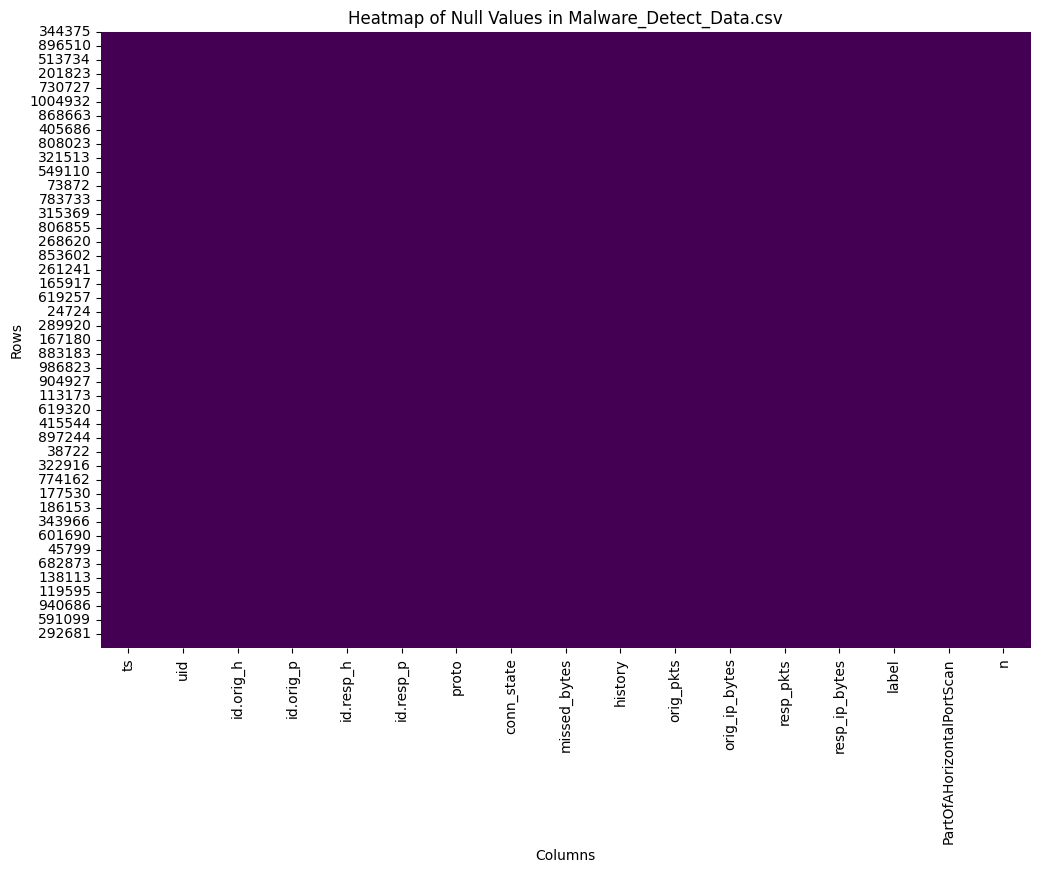

In [93]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.isnull(), cmap='viridis', cbar=False)
plt.xlabel('Columns')
plt.ylabel('Rows')
plt.title('Heatmap of Null Values in Malware_Detect_Data.csv')
plt.show()

### Timestamp
### Convert time stamp to numeric

In [94]:
#covert timestamp to numeric
df['ts'] = pd.to_numeric(df['ts'])
df['ts'].mean()

1526076054.326572

### Uid

In [95]:
# types of timestamp
df['uid'].value_counts()

uid
Cq6FWN3Ywzs95oALG2    1
CwCGQlnTa1kygROxb     1
ChnMmYSCa3PatHShd     1
CvA1i73H6vIa3h4THj    1
Cimmpk2koV6x2SnSb5    1
                     ..
CNZ0bl18Enz2EVRnn1    1
CxR8dGsiJQHgxuIn8     1
CGd0Ad2YQA9ywLn6A7    1
CXDZCQrNjXtuhLxu2     1
C1RyTE2zbiEe9INe7k    1
Name: count, Length: 196566, dtype: int64

In [96]:
df['uid']= label_encoder.fit_transform(df['uid'])
# types of timestamp
df['uid'].value_counts()

uid
165003    1
184461    1
138831    1
181159    1
142002    1
         ..
74975     1
188447    1
53001     1
105489    1
4702      1
Name: count, Length: 196566, dtype: int64

### Id.orig_h analysis

In [97]:
df['id.orig_h'].value_counts()

id.orig_h
192.168.100.103    196504
210.206.154.134         3
175.196.5.46            2
201.81.12.29            2
118.163.192.88          2
184.205.112.36          1
70.4.93.96              1
222.89.165.129          1
184.205.35.93           1
79.53.73.191            1
221.5.224.77            1
186.125.204.212         1
70.4.29.242             1
81.130.230.46           1
253.167.196.105         1
195.133.38.194          1
117.96.220.109          1
70.45.29.240            1
220.91.214.87           1
173.236.242.2           1
181.48.215.81           1
175.252.56.186          1
208.156.11.70           1
106.118.227.251         1
197.7.161.230           1
24.154.127.106          1
174.154.68.156          1
31.134.1.131            1
218.61.203.113          1
110.89.36.93            1
192.168.100.1           1
223.79.110.210          1
108.119.115.232         1
154.201.189.106         1
108.111.187.69          1
173.119.247.102         1
191.139.239.120         1
178.114.200.47          1
68

In [98]:
df['id.orig_h']= label_encoder.fit_transform(df['id.orig_h'])
# types of timestamp
df['id.orig_h'].value_counts()

id.orig_h
32    196504
38         3
19         2
36         2
9          2
24         1
52         1
43         1
25         1
55         1
42         1
29         1
51         1
56         1
46         1
33         1
8          1
53         1
41         1
16         1
22         1
20         1
37         1
0          1
34         1
45         1
18         1
47         1
39         1
6          1
31         1
44         1
4          1
11         1
2          1
12         1
30         1
21         1
48         1
57         1
15         1
3          1
26         1
40         1
54         1
13         1
17         1
1          1
23         1
27         1
10         1
50         1
14         1
49         1
5          1
28         1
7          1
35         1
Name: count, dtype: int64

### id.resp_h analysis

In [99]:
df['id.resp_h'].value_counts()

id.resp_h
147.231.100.5      887
89.221.214.130     304
213.239.154.12     293
37.187.104.44      278
192.168.100.103     62
                  ... 
226.170.84.29        1
31.31.8.190          1
158.78.202.145       1
114.19.233.206       1
75.10.105.178        1
Name: count, Length: 172517, dtype: int64

In [100]:
df['id.resp_h']= label_encoder.fit_transform(df['id.resp_h'])
df['id.resp_h'].value_counts()

id.resp_h
39585     887
163650    304
94905     293
121527    278
76879      62
         ... 
102917      1
117661      1
48583       1
12662       1
151656      1
Name: count, Length: 172517, dtype: int64

### id.resp_p analysis

In [101]:
df['id.resp_p'].value_counts()

id.resp_p
23.0       53870
8080.0     26904
2323.0     17397
9527.0      8772
123.0       1763
           ...  
49740.0        1
17990.0        1
28061.0        1
40304.0        1
28558.0        1
Name: count, Length: 48066, dtype: int64

In [102]:
df['id.resp_p']= label_encoder.fit_transform(df['id.resp_p'])
df['id.resp_p'].value_counts()

id.resp_p
19       53870
5902     26904
1707     17397
6961      8772
93        1763
         ...  
36485        1
13154        1
20555        1
29545        1
20929        1
Name: count, Length: 48066, dtype: int64

### id.orig_p analysis

In [103]:
df['id.orig_p'].value_counts()

id.orig_p
43763.0    79189
123.0       1762
23.0          42
48504.0       17
37770.0       17
           ...  
35606.0        1
47264.0        1
37256.0        1
56371.0        1
42392.0        1
Name: count, Length: 27310, dtype: int64

In [104]:
df['id.orig_p']= label_encoder.fit_transform(df['id.orig_p'])
df['id.orig_p'].value_counts()

id.orig_p
10610    79189
1         1762
0           42
15201       17
4849        17
         ...  
2757         1
13986        1
4361         1
22827        1
9294         1
Name: count, Length: 27310, dtype: int64

### proto analysis

In [105]:
df['proto'].value_counts()

proto
tcp    115617
udp     80949
Name: count, dtype: int64

In [106]:
# one hot encode proto
onehot = pd.get_dummies(df['proto'])
df = df.join(onehot)
df.head()

,ts,uid,id.orig_h,id.orig_p,id.resp_h,id.resp_p,proto,conn_state,missed_bytes,history,orig_pkts,orig_ip_bytes,resp_pkts,resp_ip_bytes,label,PartOfAHorizontalPortScan,n,tcp,udp
344375,1.526010e+09,165003,32,20388,17658,19,tcp,S0,0.0,13,1.0,60.0,0.0,0.0,1,True,False,True,False
883270,1.526229e+09,158451,32,3623,140852,6961,tcp,S0,0.0,13,1.0,60.0,0.0,0.0,1,True,False,True,False
94977,1.525915e+09,15475,32,22605,6794,6961,tcp,S0,0.0,13,2.0,120.0,0.0,0.0,1,True,False,True,False
552763,1.526090e+09,184095,32,10610,60185,30455,udp,S0,0.0,1,1.0,40.0,0.0,0.0,0,False,True,False,True
796999,1.526191e+09,102158,32,7023,28520,1707,tcp,S0,0.0,13,1.0,60.0,0.0,0.0,1,True,False,True,False


In [107]:
df.drop(['proto'],axis=1,inplace=True)
df.head()

,ts,uid,id.orig_h,id.orig_p,id.resp_h,id.resp_p,conn_state,missed_bytes,history,orig_pkts,orig_ip_bytes,resp_pkts,resp_ip_bytes,label,PartOfAHorizontalPortScan,n,tcp,udp
344375,1.526010e+09,165003,32,20388,17658,19,S0,0.0,13,1.0,60.0,0.0,0.0,1,True,False,True,False
883270,1.526229e+09,158451,32,3623,140852,6961,S0,0.0,13,1.0,60.0,0.0,0.0,1,True,False,True,False
94977,1.525915e+09,15475,32,22605,6794,6961,S0,0.0,13,2.0,120.0,0.0,0.0,1,True,False,True,False
552763,1.526090e+09,184095,32,10610,60185,30455,S0,0.0,1,1.0,40.0,0.0,0.0,0,False,True,False,True
796999,1.526191e+09,102158,32,7023,28520,1707,S0,0.0,13,1.0,60.0,0.0,0.0,1,True,False,True,False


### conn_state analysis

In [108]:
df['conn_state'].value_counts()

conn_state
S0        192498
SF          2836
REJ          891
RSTR         266
RSTOS0        45
RSTRH         12
RSTO           7
SH             6
S2             3
S1             2
Name: count, dtype: int64

In [109]:
#label encode conn_state
df['conn_state']= label_encoder.fit_transform(df['conn_state'])
df['conn_state'].value_counts()

conn_state
5    192498
8      2836
0       891
3       266
2        45
4        12
1         7
9         6
7         3
6         2
Name: count, dtype: int64

In [110]:
df['missed_bytes'].value_counts()

missed_bytes
0.0    196566
Name: count, dtype: int64

In [111]:
df['missed_bytes'].nunique()

1

In [112]:
#drop column
df.drop(['missed_bytes'],axis=1,inplace=True)

orig_pkts analysis

In [113]:
df['orig_pkts'].value_counts()

orig_pkts
1.0     156986
3.0      37726
5.0        439
4.0        183
2.0        182
8.0        103
28.0        93
29.0        61
27.0        59
26.0        57
24.0        55
12.0        49
23.0        48
15.0        44
11.0        42
13.0        40
25.0        35
9.0         34
22.0        29
18.0        27
7.0         25
30.0        23
6.0         20
45.0        20
19.0        20
20.0        18
21.0        18
14.0        17
31.0        15
44.0        15
10.0        11
16.0        11
0.0          8
32.0         6
39.0         5
17.0         5
46.0         5
37.0         4
43.0         4
35.0         4
38.0         4
36.0         4
33.0         3
34.0         3
47.0         2
40.0         2
41.0         1
48.0         1
Name: count, dtype: int64

In [114]:
df['orig_pkts'] = pd.to_numeric(df['orig_pkts'])

### orig_ip bytes

In [115]:
df['orig_ip_bytes'] = pd.to_numeric(df['orig_ip_bytes'])

### resp_pkts

In [116]:
df['resp_pkts'] = pd.to_numeric(df['resp_pkts'])

### resp_ip_bytes

In [117]:
df['resp_ip_bytes'] = pd.to_numeric(df['resp_ip_bytes'])

### label

In [118]:
df['label'].value_counts()

label
1    106943
0     89623
Name: count, dtype: int64

In [119]:
#label encode label
df['label']= label_encoder.fit_transform(df['label'])
df.head()

,ts,uid,id.orig_h,id.orig_p,id.resp_h,id.resp_p,conn_state,history,orig_pkts,orig_ip_bytes,resp_pkts,resp_ip_bytes,label,PartOfAHorizontalPortScan,n,tcp,udp
344375,1.526010e+09,165003,32,20388,17658,19,5,13,1.0,60.0,0.0,0.0,1,True,False,True,False
883270,1.526229e+09,158451,32,3623,140852,6961,5,13,1.0,60.0,0.0,0.0,1,True,False,True,False
94977,1.525915e+09,15475,32,22605,6794,6961,5,13,2.0,120.0,0.0,0.0,1,True,False,True,False
552763,1.526090e+09,184095,32,10610,60185,30455,5,1,1.0,40.0,0.0,0.0,0,False,True,False,True
796999,1.526191e+09,102158,32,7023,28520,1707,5,13,1.0,60.0,0.0,0.0,1,True,False,True,False


### ***Training the model***

### Split to train and test

In [120]:
from sklearn.model_selection import train_test_split

X = df.drop('label', axis=1)
y = df['label']

# Split the DataFrame into X and y
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
y_train.head()
y_train.value_counts()

label
1    85547
0    71705
Name: count, dtype: int64

### Normalizer

In [121]:
from sklearn.preprocessing import Normalizer

scaler = Normalizer()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### ***Model Training***

### SVM Model

In [122]:
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score

In [123]:
# from sklearn.model_selection import GridSearchCV
# from sklearn.svm import SVC

# # Assuming you have X_train_scaled, y_train defined

# # Define the hyperparameter grid
# param_grid = {'C': [0.001,0.01,0.1, 1, 10], 'kernel': ['linear']}

# # Create the GridSearchCV object
# grid_search = GridSearchCV(SVC(gamma='scale'), param_grid, cv=5)
# grid_search.fit(X_train_scaled, y_train)

# # Get the best hyperparameters
# best_params = grid_search.best_params_

# # Create a new model with the best hyperparameters
# svm_model = SVC(kernel=best_params['kernel'], C=best_params['C'], gamma='scale')
# svm_model.fit(X_train_scaled, y_train)

### Training

In [124]:
svm_model = SVC(kernel='linear', C=0.001, gamma='scale')
svm_model.fit(X_train_scaled,y_train)

SVC(C=0.001, kernel='linear')

### Making predicitions

In [125]:
# Make predictions on the test set
y_pred = svm_model.predict(X_test)

c:\Users\emon1\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(


### Evaluating the model

In [126]:
# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy}")
print(f"Classification Report:\n{report}")

Accuracy: 0.8021315561886351
Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.78      0.78     17918
           1       0.82      0.82      0.82     21396

    accuracy                           0.80     39314
   macro avg       0.80      0.80      0.80     39314
weighted avg       0.80      0.80      0.80     39314



In [ ]:
# from sklearn.model_selection import cross_val_score, KFold

# # number of folds for cross-validation
# k_folds = 10

# kf = KFold(n_splits=k_folds, shuffle=True, random_state=42)

# clf_svm =svm_model

# # performing k-fold cross-validation
# cross_val_results = cross_val_score(clf_svm, X_train_scaled, y_train, cv=kf, scoring='accuracy')

# # results
# print(f'Cross-validation results: {cross_val_results}')
# print(f'Mean accuracy: {cross_val_results.mean()}')

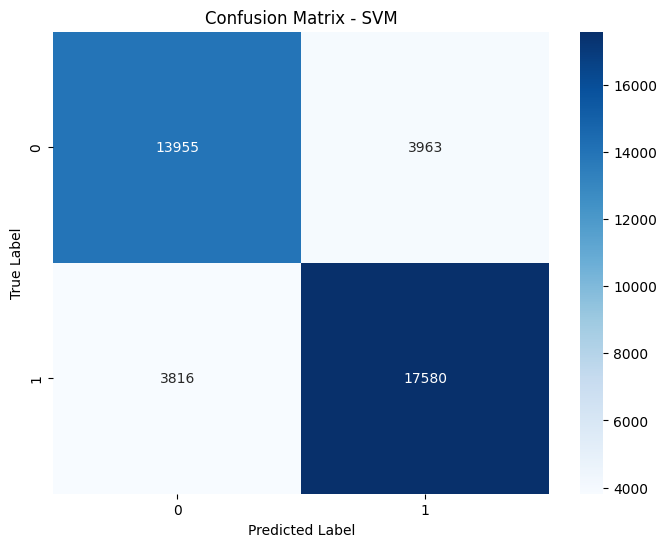

In [127]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

# Compute the confusion matrix
conf_matrix_nb = confusion_matrix(y_test, y_pred)

# Display the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_nb, annot=True, fmt='d', cmap='Blues', xticklabels=['0', '1'], yticklabels=['0', '1'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - SVM')
plt.show()

### Naive Bayes

In [ ]:
nb_model = GaussianNB()

nb_model.fit(X_train, y_train)

accuracy_nb = accuracy_score(y_test, y_pred_nb)
report_nb = classification_report(y_test, y_pred_nb)

print(f"Accuracy (Naive Bayes): {accuracy_nb}")
print(f"Classification Report (Naive Bayes):\n{report_nb}")

In [128]:
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()

### Training

In [129]:
nb_model.fit(X_train, y_train)

GaussianNB()

###  Making predictions

In [130]:
y_pred_nb = nb_model.predict(X_test)

###  Evaluating the model

In [131]:
accuracy_nb = accuracy_score(y_test, y_pred_nb)
report_nb = classification_report(y_test, y_pred_nb)

print(f"Accuracy (Naive Bayes): {accuracy_nb}")
print(f"Classification Report (Naive Bayes):\n{report_nb}")

Accuracy (Naive Bayes): 0.8689016635295315
Classification Report (Naive Bayes):
              precision    recall  f1-score   support

           0       0.80      0.96      0.87     17918
           1       0.96      0.79      0.87     21396

    accuracy                           0.87     39314
   macro avg       0.88      0.88      0.87     39314
weighted avg       0.88      0.87      0.87     39314



In [ ]:
# from sklearn.model_selection import cross_val_score, KFold

# # number of folds for cross-validation
# k_folds = 10

# kf = KFold(n_splits=k_folds, shuffle=True, random_state=42)

# clf_nb =nb_model

# # performing k-fold cross-validation
# cross_val_results = cross_val_score(clf_nb, X_train_scaled, y_train, cv=kf, scoring='accuracy')

# # results
# print(f'Cross-validation results: {cross_val_results}')
# print(f'Mean accuracy: {cross_val_results.mean()}')

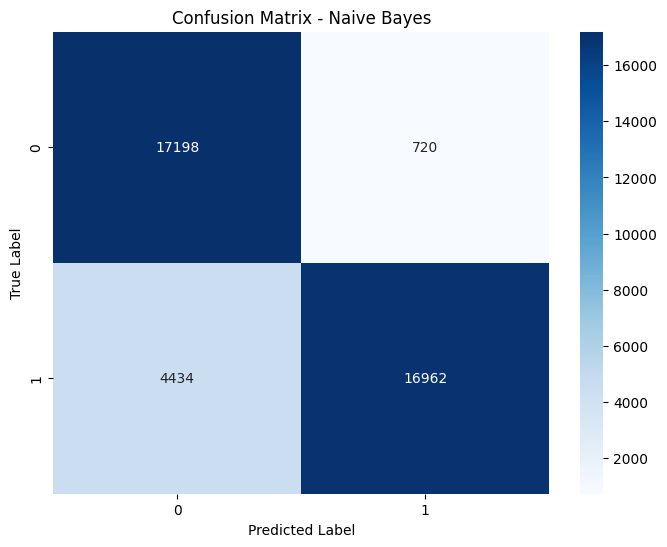

In [132]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Compute the confusion matrix
conf_matrix_nb = confusion_matrix(y_test, y_pred_nb)

# Display the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_nb, annot=True, fmt='d', cmap='Blues', xticklabels=['0', '1'], yticklabels=['0', '1'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Naive Bayes')
plt.show()

In [136]:

# 🧠 Classification Algorithms
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from xgboost import XGBClassifier
# from lightgbm import LGBMClassifier

In [ ]:
# All Models (SVC excluded)
models = {
    "Naive Bayes": GaussianNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(),
    "Gradient Boosting": GradientBoostingClassifier(),
    "AdaBoost": AdaBoostClassifier(),
    "K-Nearest Neighbors": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(),
    "Linear Discriminant Analysis": LinearDiscriminantAnalysis(),
    "Quadratic Discriminant Analysis": QuadraticDiscriminantAnalysis(),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='logloss')
    # "LightGBM": LGBMClassifier()
}

In [139]:
# Training Loop + Accuracy Storage
model_accuracies = {}

for name, model in models.items():
    print(f"\n Training: {name}")
    try:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        acc = accuracy_score(y_test, y_pred)
        model_accuracies[name] = acc

        report = classification_report(y_test, y_pred)
        print(f" Accuracy: {acc:.4f}")
        print(f" Classification Report:\n{report}")
    except Exception as e:
        print(f" Error training {name}: {e}")


 Training: Naive Bayes
 Accuracy: 0.8689
 Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.96      0.87     17918
           1       0.96      0.79      0.87     21396

    accuracy                           0.87     39314
   macro avg       0.88      0.88      0.87     39314
weighted avg       0.88      0.87      0.87     39314


 Training: Logistic Regression
 Accuracy: 0.8900
 Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.82      0.87     17918
           1       0.86      0.95      0.90     21396

    accuracy                           0.89     39314
   macro avg       0.90      0.88      0.89     39314
weighted avg       0.89      0.89      0.89     39314


 Training: Random Forest
 Accuracy: 1.0000
 Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     17918
           1       1.00      

c:\Users\emon1\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
c:\Users\emon1\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(


 Accuracy: 1.0000
 Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     17918
           1       1.00      1.00      1.00     21396

    accuracy                           1.00     39314
   macro avg       1.00      1.00      1.00     39314
weighted avg       1.00      1.00      1.00     39314


 Training: XGBoost


c:\Users\emon1\AppData\Local\Programs\Python\Python311\Lib\site-packages\xgboost\training.py:183: UserWarning: [23:47:10] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


 Accuracy: 1.0000
 Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     17918
           1       1.00      1.00      1.00     21396

    accuracy                           1.00     39314
   macro avg       1.00      1.00      1.00     39314
weighted avg       1.00      1.00      1.00     39314



C:\Users\emon1\AppData\Local\Temp\ipykernel_3084\940167888.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(model_accuracies.keys()), y=list(model_accuracies.values()), palette='viridis')


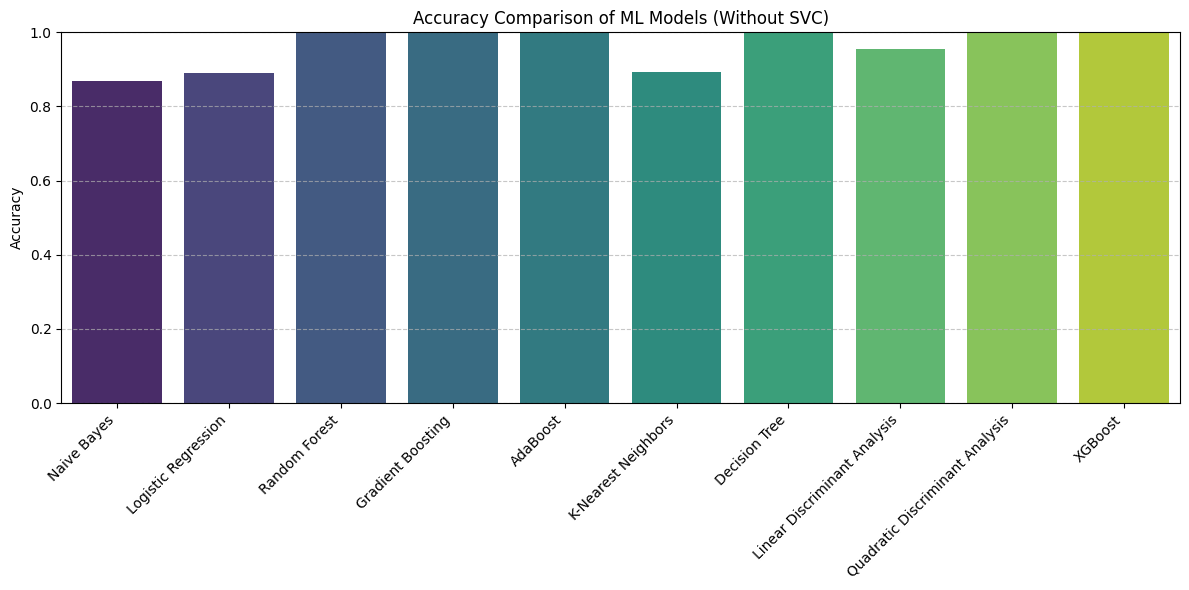

In [140]:
# Accuracy Bar Plot
plt.figure(figsize=(12, 6))
sns.barplot(x=list(model_accuracies.keys()), y=list(model_accuracies.values()), palette='viridis')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Accuracy')
plt.ylim(0, 1.0)
plt.title('Accuracy Comparison of ML Models (Without SVC)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()